# MSCS 634 | Final Online Retail Data Mining Project
Rajasekhar Reddy Kayyam — University of the Cumberlands

Run all cells from the repository root. Prior executed outputs are retained; the combined notebook has not been re-executed end to end.

## Phase 1 — Data preparation and EDA

## 1. Obtain the dataset
 The original dataset has 541,909 rows and 8 columns.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file = Path("Online Retail.xlsx")
if not file.exists():
    raise FileNotFoundError("Download and extract Online Retail.xlsx from the UCI link in the cell above, then place it next to this notebook.")
df = pd.read_excel(file, engine="openpyxl")
print("Original shape:", df.shape)
display(df.head())

Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Dataset description and structure
Each row is an invoice line item. InvoiceNo identifies a transaction; StockCode identifies a product; Quantity and UnitPrice support revenue calculations. CustomerID is missing for some rows. Negative quantities and invoices starting with C often represent returns/cancellations, which require explicit handling.

In [9]:
print(df.info())

display(df.describe(include="all").T)

print("Missing values:\n", df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


## 3. Clean and document choices
Remove exact duplicates. For customer-based analysis, exclude records without CustomerID (do not invent identities). Exclude cancellations, nonpositive quantities, and nonpositive prices from *purchase* analysis. Preserve original data separately; this is a documented business choice, not a claim that returns are invalid.

In [13]:
clean = df.drop_duplicates().copy()

clean["InvoiceNo"] = clean["InvoiceNo"].astype(str)

clean["Description"] = clean["Description"].astype("string").str.strip()

clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")

rows_after_dedup = len(clean)

clean = clean.dropna(
    subset=["CustomerID", "InvoiceDate", "StockCode", "Description"]
)

clean = clean[
    (~clean["InvoiceNo"].str.startswith("C")) &
    (clean["Quantity"] > 0) &
    (clean["UnitPrice"] > 0)
].copy()

clean["CustomerID"] = clean["CustomerID"].astype(int)

print("Original rows:", len(df))
print("After deduplication:", rows_after_dedup)
print("Clean purchase rows:", len(clean))
print("Missing values after cleaning:\n", clean.isna().sum())

Original rows: 541909
After deduplication: 536641
Clean purchase rows: 392692
Missing values after cleaning:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


## 4. Feature engineering
Create derived columns useful for analysis and later deliverables: `LineRevenue`, `PurchaseMonth`, `PurchaseHour`, `PurchaseDayOfWeek`, and `IsWeekend`. The dataset now contains at least 10 attributes.

In [14]:
clean["LineRevenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["PurchaseMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["PurchaseHour"] = clean["InvoiceDate"].dt.hour
clean["PurchaseDayOfWeek"] = clean["InvoiceDate"].dt.day_name()
clean["IsWeekend"] = clean["InvoiceDate"].dt.dayofweek >= 5
print("Cleaned dataset shape:", clean.shape)
display(clean.head())

Cleaned dataset shape: (392692, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue,PurchaseMonth,PurchaseHour,PurchaseDayOfWeek,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,8,Wednesday,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,8,Wednesday,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False


## 5. Explore outliers without silently deleting valid large orders
Use IQR to flag unusually large line revenues. High-value purchases may be legitimate; we retain them in the cleaned export and discuss robust transformations for later modeling.

In [15]:
q1, q3 = clean["LineRevenue"].quantile([0.25, 0.75])
iqr = q3-q1
upper = q3+1.5*iqr
flagged = clean[clean["LineRevenue"] > upper]
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, upper fence={upper:.2f}")
print("High-value line items flagged:",len(flagged),"of",len(clean))

Q1=4.95, Q3=19.80, IQR=14.85, upper fence=42.07
High-value line items flagged: 31231 of 392692


## 6. Exploratory visualizations

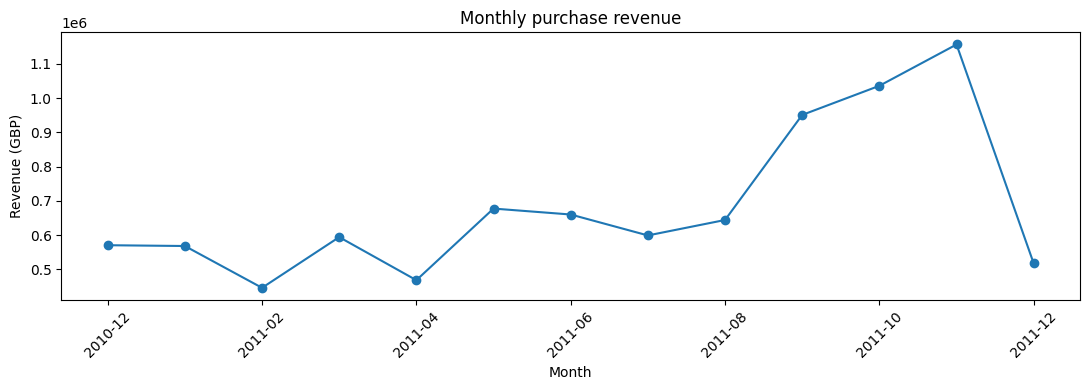

In [16]:
monthly = clean.groupby("PurchaseMonth")["LineRevenue"].sum().sort_index()
ax = monthly.plot(figsize=(11,4), marker="o", title="Monthly purchase revenue")
ax.set(xlabel="Month",ylabel="Revenue (GBP)")
plt.xticks(rotation=45);plt.tight_layout();plt.show()

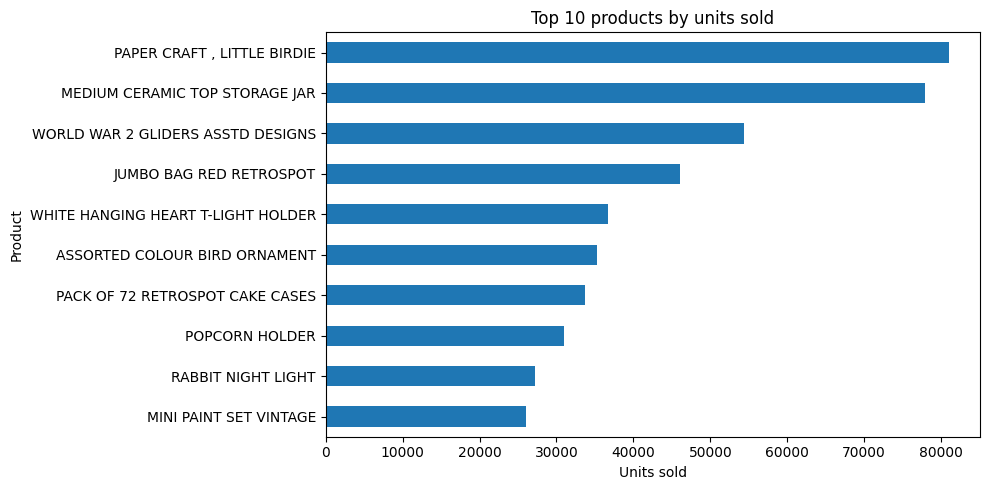

In [17]:
top = clean.groupby("Description")["Quantity"].sum().nlargest(10).sort_values()
ax = top.plot.barh(figsize=(10,5), title="Top 10 products by units sold")
ax.set(xlabel="Units sold",ylabel="Product");plt.tight_layout();plt.show()

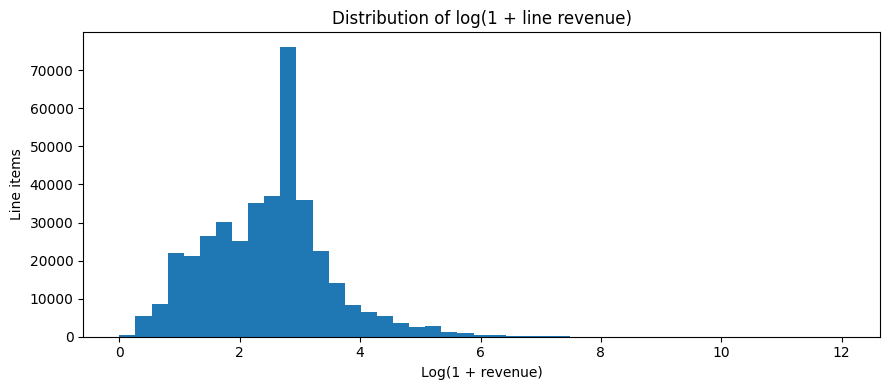

In [18]:
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(np.log1p(clean["LineRevenue"]),bins=45)
ax.set(title="Distribution of log(1 + line revenue)",xlabel="Log(1 + revenue)",ylabel="Line items")
plt.tight_layout();plt.show()

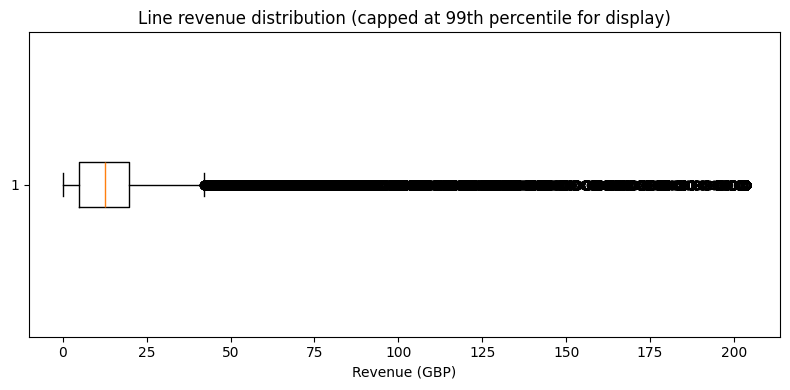

In [19]:
fig,ax=plt.subplots(figsize=(8,4))
ax.boxplot(clean["LineRevenue"].clip(upper=clean["LineRevenue"].quantile(.99)),vert=False)
ax.set(title="Line revenue distribution (capped at 99th percentile for display)",xlabel="Revenue (GBP)")
plt.tight_layout();plt.show()

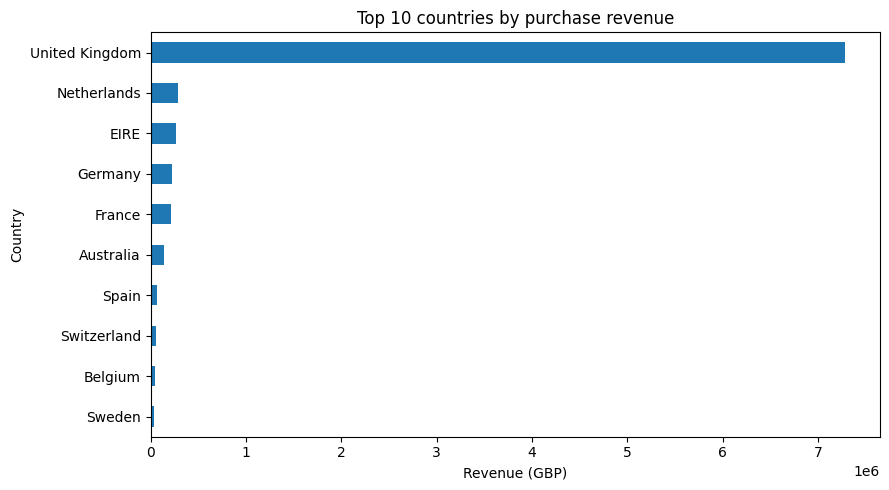

In [20]:
country = clean.groupby("Country")["LineRevenue"].sum().nlargest(10).sort_values()
ax = country.plot.barh(figsize=(9,5), title="Top 10 countries by purchase revenue")
ax.set(xlabel="Revenue (GBP)",ylabel="Country");plt.tight_layout();plt.show()

## 7. Statistics and feature relationships

,count,mean,std,min,25%,50%,75%,max
Quantity,392692.0,13.119702,180.492832,1.000,2.00,6.00,12.00,80995.00
UnitPrice,392692.0,3.125914,22.241836,0.001,1.25,1.95,3.75,8142.75
LineRevenue,392692.0,22.631500,311.099224,0.001,4.95,12.45,19.80,168469.60
PurchaseHour,392692.0,12.721532,2.276661,6.000,11.00,13.00,14.00,20.00


,Quantity,UnitPrice,LineRevenue,PurchaseHour
Quantity,1.000000,-0.004578,0.914451,-0.014665
UnitPrice,-0.004578,1.000000,0.081619,-0.000217
LineRevenue,0.914451,0.081619,1.000000,-0.013093
PurchaseHour,-0.014665,-0.000217,-0.013093,1.000000


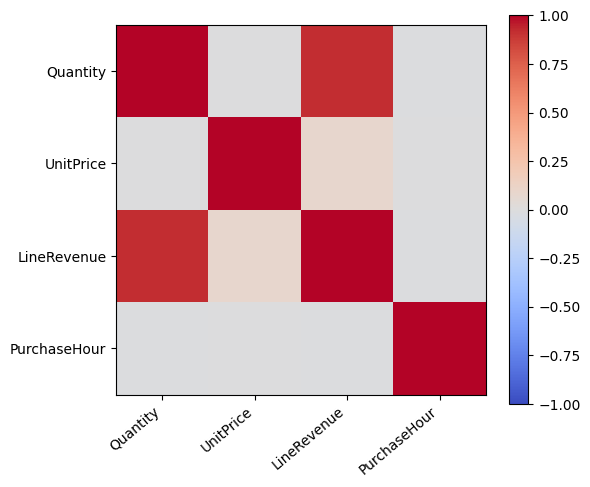

In [21]:
display(clean[["Quantity","UnitPrice","LineRevenue","PurchaseHour"]].describe().T)
correlations=clean[["Quantity","UnitPrice","LineRevenue","PurchaseHour"]].corr()
display(correlations)
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(correlations, vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(correlations.columns)),correlations.columns,rotation=40,ha="right")
ax.set_yticks(range(len(correlations.index)),correlations.index)
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()

## 8. Customer-level features for later deliverables
One row per customer provides frequency, total spending, average line revenue, and number of distinct products. Later deliverables must avoid using features that leak the target being predicted.

In [22]:
customer = clean.groupby("CustomerID").agg(
    TotalSpend=("LineRevenue","sum"),
    PurchaseLines=("InvoiceNo","size"),
    InvoiceCount=("InvoiceNo","nunique"),
    UniqueProducts=("StockCode","nunique"),
    AvgLineRevenue=("LineRevenue","mean")
).reset_index()
print("Customer-level shape:",customer.shape)
display(customer.head())
clean.to_csv("online_retail_cleaned.csv",index=False)
customer.to_csv("online_retail_customer_features.csv",index=False)
print("Saved cleaned transaction and customer feature CSVs.")

Customer-level shape: (4338, 6)


,CustomerID,TotalSpend,PurchaseLines,InvoiceCount,UniqueProducts,AvgLineRevenue
0,12346,77183.60,1,1,1,77183.600000
1,12347,4310.00,182,7,103,23.681319
2,12348,1797.24,31,4,22,57.975484
3,12349,1757.55,73,1,73,24.076027
4,12350,334.40,17,1,17,19.670588


Saved cleaned transaction and customer feature CSVs.


In [23]:
# Highest-revenue month
print("Highest revenue month:")
print(
    clean.assign(
        Month=clean["InvoiceDate"].dt.to_period("M"),
        Revenue=clean["Quantity"] * clean["UnitPrice"]
    ).groupby("Month")["Revenue"].sum().sort_values(ascending=False).head(1)
)

# Top-selling product
print("\nTop-selling product:")
print(
    clean.groupby("Description")["Quantity"]
    .sum().sort_values(ascending=False).head(1)
)

# Revenue outliers using IQR
revenue = clean["Quantity"] * clean["UnitPrice"]
q1 = revenue.quantile(0.25)
q3 = revenue.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print("\nNumber of high-value outliers:", (revenue > upper).sum())

# Correlation matrix
print("\nCorrelation matrix:")
print(
    clean.assign(Revenue=revenue)[
        ["Quantity", "UnitPrice", "Revenue"]
    ].corr()
)

Highest revenue month:
Month
2011-11    1156205.61
Freq: M, Name: Revenue, dtype: float64

Top-selling product:
Description
PAPER CRAFT , LITTLE BIRDIE    80995
Name: Quantity, dtype: int64

Number of high-value outliers: 31231

Correlation matrix:
           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.004578  0.914451
UnitPrice -0.004578   1.000000  0.081619
Revenue    0.914451   0.081619  1.000000


## Phase 2 — Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv(
    "online_retail_cleaned.csv",
    parse_dates=["InvoiceDate"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (392692, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue,PurchaseMonth,PurchaseHour,PurchaseDayOfWeek,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,8,Wednesday,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,8,Wednesday,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False


In [2]:
cutoff = pd.Timestamp("2011-09-01")
end = pd.Timestamp("2011-12-01")

history = df[df["InvoiceDate"] < cutoff].copy()

future = df[
    (df["InvoiceDate"] >= cutoff) &
    (df["InvoiceDate"] < end)
].copy()

features = history.groupby("CustomerID").agg(
    PastSpend=("LineRevenue", "sum"),
    PurchaseLines=("InvoiceNo", "size"),
    InvoiceCount=("InvoiceNo", "nunique"),
    UniqueProducts=("StockCode", "nunique"),
    AvgLineRevenue=("LineRevenue", "mean")
)

target = future.groupby("CustomerID")["LineRevenue"].sum()

data = features.join(target.rename("FutureSpend"))
data["FutureSpend"] = data["FutureSpend"].fillna(0)

print(data.shape)
display(data.head())

(3317, 6)


,PastSpend,PurchaseLines,InvoiceCount,UniqueProducts,AvgLineRevenue,FutureSpend
CustomerID,,,,,,
12346,77183.60,1,1,1,77183.600000,0.00
12347,2790.86,124,5,82,22.506935,1294.32
12348,1487.24,28,3,22,53.115714,310.00
12350,334.40,17,1,17,19.670588,0.00
12352,1561.81,38,5,26,41.100263,944.23


In [3]:
X = data.drop(columns=["FutureSpend"])
y = np.log1p(data["FutureSpend"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=10)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=0.1, max_iter=20000)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = np.expm1(model.predict(X_test))
    actual = np.expm1(y_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "MSE": mean_squared_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

comparison = pd.DataFrame(results)
display(comparison)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7796.330111,1.869123e+10,136715.883574,-456.420823
1,Ridge Regression,7562.111165,1.646723e+10,128324.693469,-401.993884
2,Lasso Regression,20101.950350,2.285929e+11,478113.942288,-5593.236216


In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    print(name)
    print("Mean CV R2:", scores["test_score"].mean())

Linear Regression
Mean CV R2: 0.10360743650020447
Ridge Regression
Mean CV R2: 0.106565168013907
Lasso Regression
Mean CV R2: 0.12728322294724065


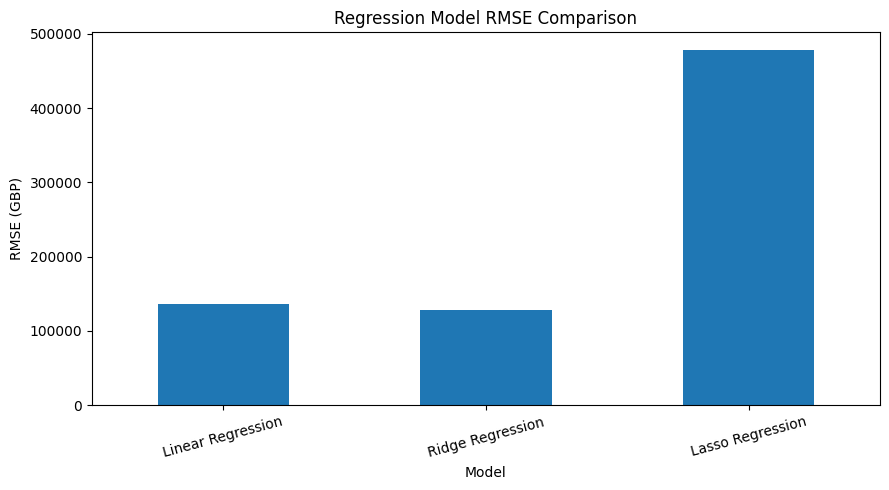

In [5]:
comparison.plot(
    x="Model",
    y="RMSE",
    kind="bar",
    legend=False,
    figsize=(9, 5),
    title="Regression Model RMSE Comparison"
)

plt.ylabel("RMSE (GBP)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("model_rmse_comparison.png", dpi=200)
plt.show()

## Phase 3 — Classification, clustering and pattern mining

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
from collections import Counter
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from IPython.display import display
out = Path('figures'); out.mkdir(exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(out / (name + '.png'), dpi=150, bbox_inches='tight'); plt.show()
df = pd.read_csv('online_retail_cleaned.csv', parse_dates=['InvoiceDate'], dtype={'StockCode':str,'InvoiceNo':str})
assert df['LineRevenue'].ge(0).all()
print('Cleaned transaction lines:', len(df))


Cleaned transaction lines: 392692


## 1. Customer features and classification target
As in Deliverable 2, historical data ends before September 1, 2011; the outcome window runs through November 30. The binary target is 1 when a historical customer makes any positive purchase in that window, otherwise 0. This measures observed repeat purchasing, not permanent churn. Recency is added to the five earlier features. Customer identifiers are not predictors.

In [2]:
cutoff = pd.Timestamp('2011-09-01')
end = pd.Timestamp('2011-12-01')
history = df[df.InvoiceDate < cutoff].copy()
future = df[(df.InvoiceDate >= cutoff) & (df.InvoiceDate < end)]
features = history.groupby('CustomerID').agg(PastSpend=('LineRevenue','sum'), PurchaseLines=('InvoiceNo','size'), InvoiceCount=('InvoiceNo','nunique'), UniqueProducts=('StockCode','nunique'), AvgLineRevenue=('LineRevenue','mean'), LastPurchase=('InvoiceDate','max'))
features['RecencyDays'] = (cutoff - features.pop('LastPurchase')).dt.total_seconds()/86400
X = np.log1p(features)
y = pd.Series(features.index.isin(future.CustomerID).astype(int), index=features.index, name='RepeatPurchase')
print('Customers:',len(X)); display(y.value_counts().rename('Count'))
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=42,stratify=y)


Customers: 3317


RepeatPurchase
1    1871
0    1446
Name: Count, dtype: int64

## 2. Classification and tuning
A decision tree captures nonlinear interactions; KNN compares customers with similar behavior. Log transformation reduces skew, and scaling for KNN is fitted within each training fold. Grid search optimizes positive-class F1 using stratified five-fold cross-validation. Depth, minimum leaf size and class weighting control tree complexity and class balance. The test set is reserved for final evaluation.

Best parameters: {'class_weight': None, 'max_depth': 3, 'min_samples_leaf': 15}
Best CV F1: 0.7043


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Decision Tree,0.6009,0.6471,0.6453,0.6462,0.5943
KNN,0.6446,0.6915,0.6693,0.6802,0.6803
Tuned Decision Tree,0.6627,0.6951,0.7173,0.7060,0.7423


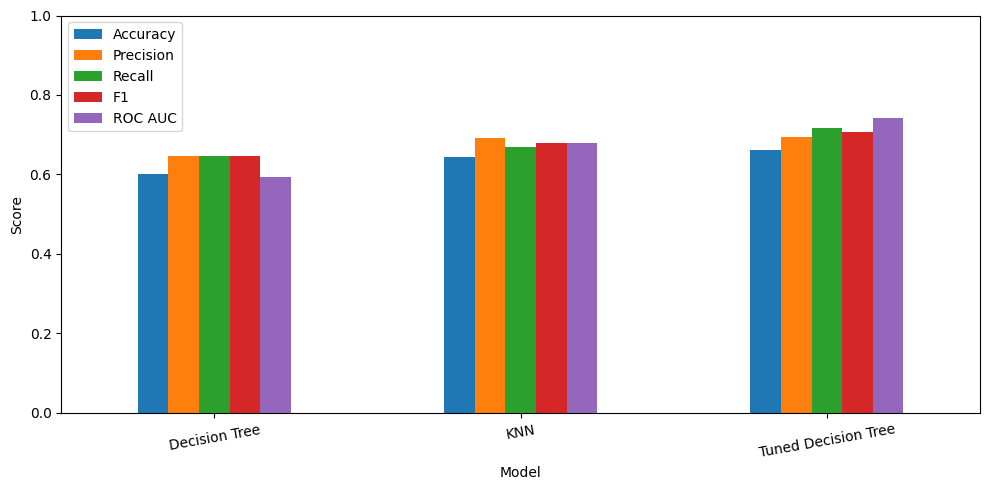

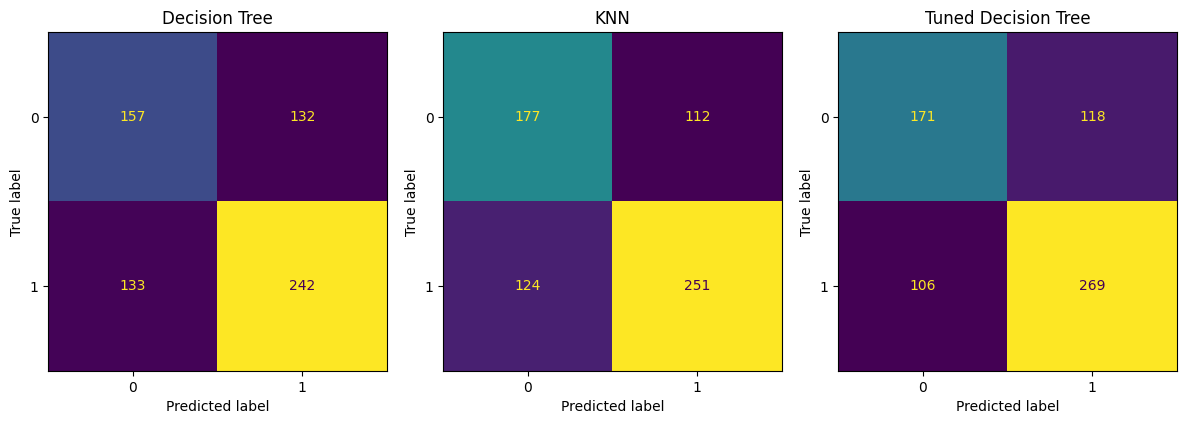

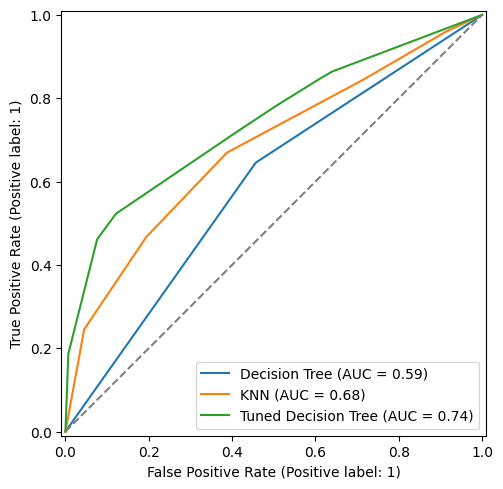

Highest held-out F1: Tuned Decision Tree


In [3]:
tree = DecisionTreeClassifier(random_state=42)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
cv = StratifiedKFold(5,shuffle=True,random_state=42)
search = GridSearchCV(tree, {'max_depth':[3,5,8,None], 'min_samples_leaf':[5,15,30], 'class_weight':[None,'balanced']}, scoring='f1',cv=cv,n_jobs=1)
search.fit(X_train,y_train)
print('Best parameters:',search.best_params_)
print('Best CV F1:',round(search.best_score_,4))
models = {'Decision Tree':tree, 'KNN':knn, 'Tuned Decision Tree':search.best_estimator_}
rows=[]
for name, model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
    rows.append([name,accuracy_score(y_test,pred),precision_score(y_test,pred,zero_division=0),recall_score(y_test,pred),f1_score(y_test,pred),roc_auc_score(y_test,prob)])
metrics=pd.DataFrame(rows,columns=['Model','Accuracy','Precision','Recall','F1','ROC AUC']).set_index('Model')
display(metrics.round(4)); metrics.to_csv('classification_metrics.csv')
metrics.plot.bar(figsize=(10,5),ylim=(0,1),rot=10); plt.ylabel('Score'); save('classification_comparison')
fig,axes=plt.subplots(1,3,figsize=(12,4))
for (name,model),ax in zip(models.items(),axes):
    ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,ax=ax,colorbar=False); ax.set_title(name)
save('confusion_matrices')
fig,ax=plt.subplots(figsize=(7,5))
for name,model in models.items(): RocCurveDisplay.from_estimator(model,X_test,y_test,name=name,ax=ax)
ax.plot([0,1],[0,1],'--',color='gray'); save('roc_curves')
print('Highest held-out F1:',metrics.F1.idxmax())


## 3. Customer segmentation
K-Means uses historical recency, spending, frequency and product diversity. Log transformation and standardization reduce scale effects. Compare k=2–6 using silhouette scores, then describe clusters using original-unit medians. PCA is used only for visualization; clustering uses all selected features.

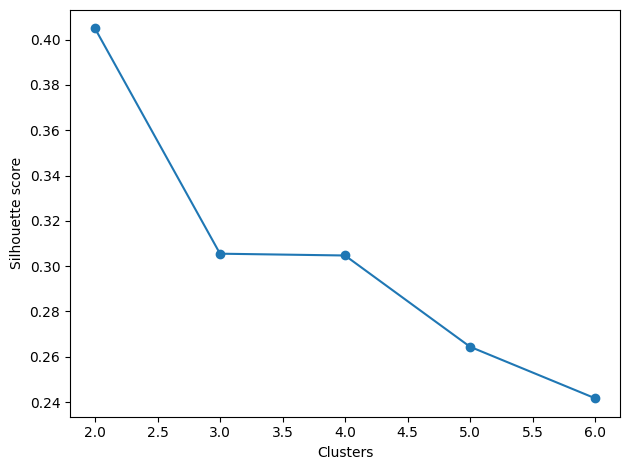

,Customers,PastSpend,InvoiceCount,UniqueProducts,RecencyDays
Cluster,,,,,
0,1278,1627.79,4.0,70.0,26.40
1,2039,309.80,1.0,17.0,115.53


Selected k: 2 Silhouette: 0.4049


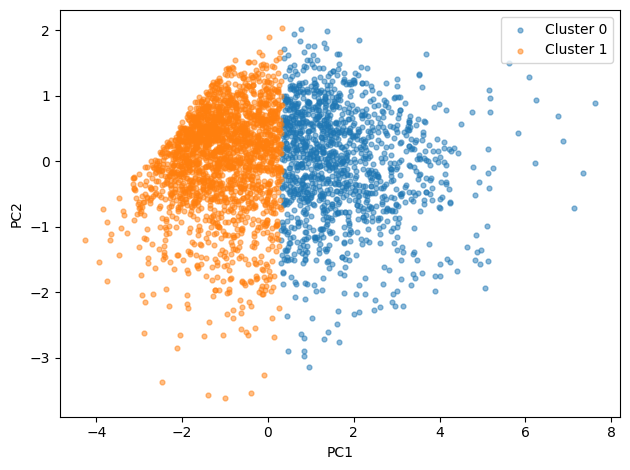

In [4]:
cols=['PastSpend','InvoiceCount','UniqueProducts','RecencyDays']
Z=StandardScaler().fit_transform(X[cols])
scores={}; inertia={}
for k in range(2,7):
    km=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Z)
    scores[k]=silhouette_score(Z,km.labels_); inertia[k]=km.inertia_
plt.plot(list(scores),list(scores.values()),marker='o'); plt.xlabel('Clusters'); plt.ylabel('Silhouette score'); save('silhouette_selection')
k=max(scores,key=scores.get)
km=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Z)
seg=features.assign(Cluster=km.labels_)
profile=seg.groupby('Cluster')[cols].median(); profile.insert(0,'Customers',seg.groupby('Cluster').size())
display(profile.round(2)); profile.to_csv('cluster_profiles.csv')
print('Selected k:',k,'Silhouette:',round(scores[k],4))
xy=PCA(n_components=2).fit_transform(Z)
for label in range(k):
    mask=km.labels_==label; plt.scatter(xy[mask,0],xy[mask,1],s=12,alpha=.5,label=f'Cluster {label}')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(); save('customer_clusters')


## 4. Association rule mining (Apriori)
Use historical invoices as baskets. Products are represented by stock codes; non-merchandise codes without a leading digit are excluded, which removes alphabetic postage/fee codes but may retain numeric non-merchandise codes. A transparent Apriori implementation counts frequent singletons, then pairs and triples using downward closure. Rules require support ≥ 1%, confidence ≥ 30%, and lift > 1. Limiting itemsets to three products keeps the search tractable and does not claim to discover longer patterns.

Baskets: 11342 Frequent itemsets: 1076 Rules: 949


,Antecedent,Consequent,Support,Confidence,Lift,InvoiceCount
616,HERB MARKER CHIVES,HERB MARKER THYME + HERB MARKER PARSLEY,0.011,0.891,70.694,123
617,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER CHIVES,0.011,0.860,70.694,123
878,HERB MARKER CHIVES,HERB MARKER THYME + HERB MARKER MINT,0.011,0.884,70.613,122
879,HERB MARKER THYME + HERB MARKER MINT,HERB MARKER CHIVES,0.011,0.859,70.613,122
473,HERB MARKER THYME,HERB MARKER BASIL + HERB MARKER CHIVES,0.011,0.769,70.360,120
478,HERB MARKER BASIL + HERB MARKER CHIVES,HERB MARKER THYME,0.011,0.968,70.360,120
629,HERB MARKER PARSLEY,HERB MARKER BASIL + HERB MARKER CHIVES,0.011,0.769,70.360,120
634,HERB MARKER BASIL + HERB MARKER CHIVES,HERB MARKER PARSLEY,0.011,0.968,70.360,120
507,HERB MARKER CHIVES,HERB MARKER PARSLEY + HERB MARKER MINT,0.011,0.899,70.285,124
508,HERB MARKER PARSLEY + HERB MARKER MINT,HERB MARKER CHIVES,0.011,0.855,70.285,124


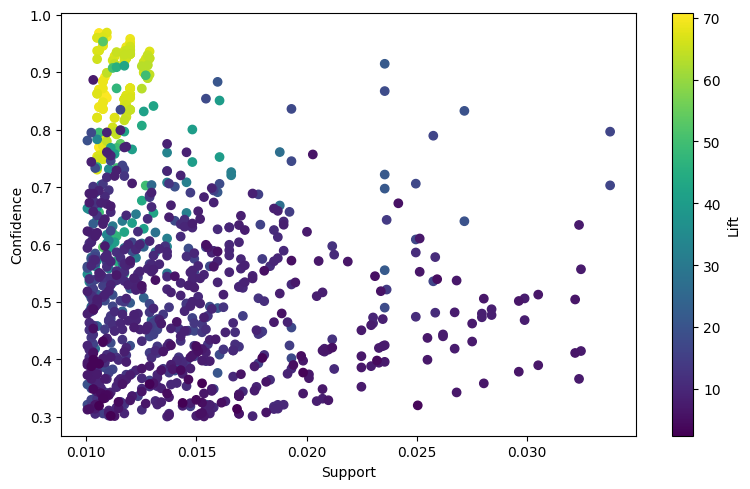

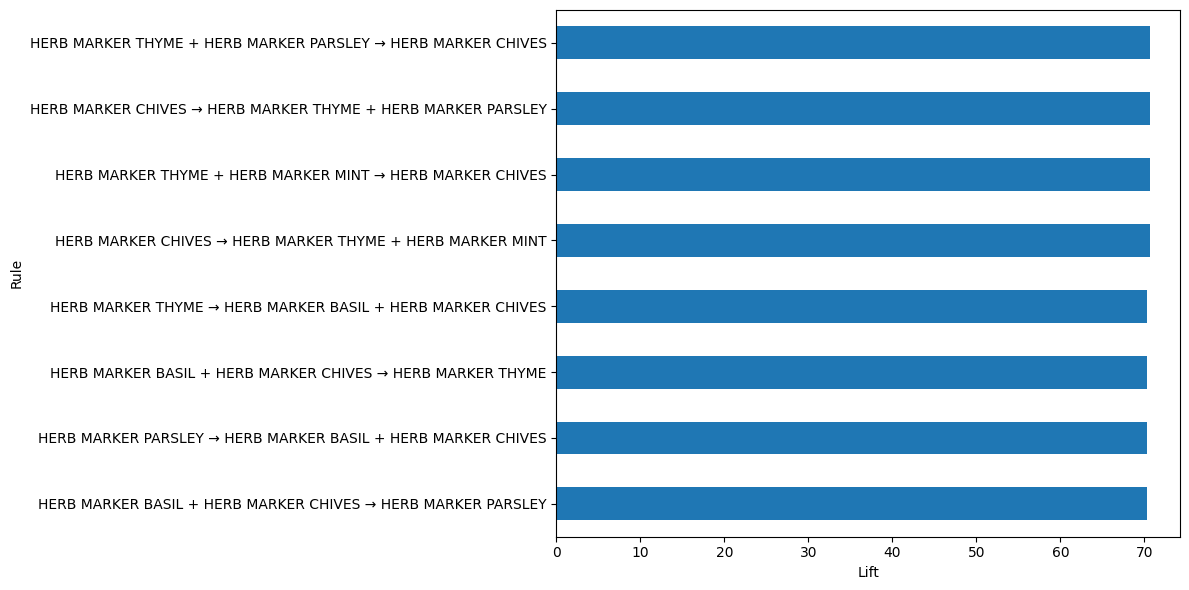

In [5]:
# Basket membership is binary, irrespective of quantity.
items=history[history.StockCode.str.match(r'^\d',na=False)].copy()
baskets=items.groupby('InvoiceNo').StockCode.agg(lambda x:set(x)).tolist()
N=len(baskets); min_support=.01; min_confidence=.30
single=Counter(x for b in baskets for x in b)
frequent={ (x,):v for x,v in single.items() if v/N>=min_support }
prev=set(frequent); universe={x[0] for x in prev}
for size in [2,3]:
    counts=Counter()
    for b in baskets:
        for candidate in combinations(sorted(b & universe),size):
            if all(sub in prev for sub in combinations(candidate,size-1)):
                counts[candidate]+=1
    prev={t for t,v in counts.items() if v/N>=min_support}
    frequent.update({t:counts[t] for t in prev})
    universe={x for t in prev for x in t}
labels=items.groupby('StockCode').Description.agg(lambda x:x.value_counts().index[0]).to_dict()
rows=[]
for itemset,count in frequent.items():
    for size in range(1,len(itemset)):
        for a in combinations(itemset,size):
            b=tuple(x for x in itemset if x not in a)
            support=count/N; confidence=count/frequent[a]; lift=confidence/(frequent[b]/N)
            if confidence>=min_confidence and lift>1:
                rows.append([' + '.join(labels[x] for x in a),' + '.join(labels[x] for x in b),support,confidence,lift,count])
rules=pd.DataFrame(rows,columns=['Antecedent','Consequent','Support','Confidence','Lift','InvoiceCount']).sort_values(['Lift','Support'],ascending=False)
print('Baskets:',N,'Frequent itemsets:',len(frequent),'Rules:',len(rules))
display(rules.head(10).round(3)); rules.to_csv('association_rules.csv',index=False)
if not rules.empty:
    plt.figure(figsize=(8,5)); sc=plt.scatter(rules.Support,rules.Confidence,c=rules.Lift,cmap='viridis'); plt.colorbar(sc,label='Lift'); plt.xlabel('Support'); plt.ylabel('Confidence'); save('association_rule_scatter')
    top=rules.head(8).copy(); top['Rule']=top.Antecedent+' → '+top.Consequent
    top.set_index('Rule').Lift.sort_values().plot.barh(figsize=(12,6)); plt.xlabel('Lift'); save('top_association_rules')


## 5. Interpretation and practical applications
The following results are generated directly from the executed analysis. Repeat-purchase scores can prioritize retention outreach, but campaign effectiveness requires prospective testing. Cluster medians support differentiated service and marketing. Association rules suggest cross-selling and merchandising opportunities; they are observational, not causal. Historical data represents a single retailer and period, so future deployment requires temporal validation.

In [6]:
best=metrics.F1.idxmax()
print(f'{best} achieved the highest test F1 ({metrics.loc[best,"F1"]:.3f}), with accuracy {metrics.loc[best,"Accuracy"]:.3f} and AUC {metrics.loc[best,"ROC AUC"]:.3f}.')
for label,r in profile.iterrows():
    print(f'Cluster {label}: {int(r.Customers)} customers; median spend £{r.PastSpend:.2f}, {r.InvoiceCount:g} invoices, {r.UniqueProducts:g} products, recency {r.RecencyDays:.1f} days.')
if len(rules):
    r=rules.iloc[0]; print(f'Top lift rule: {r.Antecedent} -> {r.Consequent}; support {r.Support:.2%}, confidence {r.Confidence:.2%}, lift {r.Lift:.2f}. Test this pairing in recommendations or bundles.')


Tuned Decision Tree achieved the highest test F1 (0.706), with accuracy 0.663 and AUC 0.742.
Cluster 0: 1278 customers; median spend £1627.79, 4 invoices, 70 products, recency 26.4 days.
Cluster 1: 2039 customers; median spend £309.80, 1 invoices, 17 products, recency 115.5 days.
Top lift rule: HERB MARKER CHIVES -> HERB MARKER THYME + HERB MARKER PARSLEY; support 1.08%, confidence 89.13%, lift 70.69. Test this pairing in recommendations or bundles.


### Observed findings
The tuned tree improved test F1 from 0.646 to 0.706 and ROC AUC from 0.594 to 0.742. Its training-only cross-validation F1 was 0.704. Cluster 0 represents active, higher-value customers (median spend £1,627.79 and recency 26.4 days); loyalty offers may suit this group. Cluster 1 represents less active, lower-spending customers (median £309.80 and recency 115.5 days); test reactivation campaigns here. The silhouette score of 0.405 indicates moderate separation, not perfectly distinct groups. The leading herb-marker rule occurs in 123 invoices; despite high lift, its low support limits reach. Test bundles and monitor incremental sales before rollout.

## References
Chen, D. (2015). *Online retail* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Agrawal, R., & Srikant, R. (1994). Fast algorithms for mining association rules. *Proceedings of the 20th International Conference on Very Large Data Bases*, 487–499.

Scikit-learn developers. (n.d.). *Scikit-learn user guide*. https://scikit-learn.org/stable/user_guide.html

## Phase 4 — Final interpretation

### Introduction and dataset
The project examines customer spending, repeat purchasing, customer segmentation, and product co-occurrence using the UCI Online Retail dataset (Chen, 2015). The original file contains 541,909 invoice lines and eight variables from a UK-based online retailer, covering December 2010 to December 2011. Transaction-level detail makes it possible to connect purchasing behavior with operational decisions without requiring customer names. The objective is to evaluate predictive usefulness rather than assume that a model is ready for deployment.

### Data preparation and exploration
Exact duplicates were removed, leaving 536,641 rows. Missing customer identifiers, invalid dates or descriptions, cancellations, and nonpositive quantities or prices were excluded, yielding 392,692 positive purchase lines and 4,338 customers. This analysis therefore measures gross positive purchases rather than net sales after returns. Revenue was calculated as quantity multiplied by unit price; month, hour, weekday and weekend indicators were derived from timestamps. The IQR upper fence was approximately £42.07; 31,231 high-value lines were flagged and retained because legitimate bulk orders may be informative. November 2011 had the highest observed monthly revenue (£1,156,205.61). PAPER CRAFT, LITTLE BIRDIE led unit volume (80,995). Quantity and revenue correlated at 0.914, partly because quantity is a component of revenue. December 2011 is incomplete, and one year cannot establish recurring seasonality.

### Regression and evaluation
Historical customer features were calculated before September 1, 2011; spending from September through November was the target, with zero assigned to existing customers who did not purchase. Five predictors captured historical spending, line count, invoice count, product diversity and average line revenue. An 80/20 customer split and standardized pipelines were used with log1p targets and expm1 predictions. Linear, Ridge (alpha 10) and Lasso (alpha 0.1) achieved held-out RMSE of £136,715.88, £128,324.69 and £478,113.94, respectively. Their GBP-scale R² values were -456.42, -401.99 and -5593.24. Ridge was least poor, not a successful forecast: all models underperformed a constant-mean benchmark on the test set. Five-fold log-scale CV R² was 0.104, 0.107 and 0.127 respectively; these scores are not comparable to GBP-scale R². Extreme inverse-transformed predictions are a plausible contributor to the large errors. Future work should test a two-part purchase/spend model, robust losses and rolling temporal validation.

### Classification and tuning
Repeat purchase in the same future window was predicted for 3,317 existing customers. Decision Tree and KNN were compared using a stratified customer holdout. GridSearchCV used five training folds and F1 scoring across 24 tree parameter combinations. The selected depth was 3, minimum leaf size 15, with no class weighting; validation F1 was 0.7043. Test accuracy/F1/AUC were 0.601/0.646/0.594 for the baseline tree, 0.645/0.680/0.680 for KNN, and 0.663/0.706/0.742 for the tuned tree. Its precision was 0.695 and recall 0.717. Confusion matrices and ROC curves reveal trade-offs between missed repeat buyers and false positives. These results support a limited retention pilot, not a guarantee of future purchasing. The holdout tests different customers within one time window, not performance in a later season.

### Customer segmentation
K-Means was fitted to log-transformed, standardized historical spending, invoice frequency, product diversity and recency. Silhouette comparison across k=2–6 selected two clusters (0.4049), suggesting moderate separation. Cluster 0 included 1,278 customers with median spend £1,627.79, four invoices, 70 products and recency 26.4 days. Cluster 1 included 2,039 customers with median spend £309.80, one invoice, 17 products and recency 115.5 days. The groups describe observed behavior rather than fixed identities. Loyalty offers and reactivation experiments are possible uses; membership should be refreshed and checked for stability.

### Association rule mining
Apriori used binary product presence in 11,342 historical merchandise-containing invoices, minimum support 1%, confidence 30%, lift above one and a maximum itemset size of three (Agrawal & Srikant, 1994). It produced 1,076 frequent itemsets and 949 directional rules. The strongest lift rule linked HERB MARKER CHIVES to HERB MARKER THYME and HERB MARKER PARSLEY, with 1.08% support, 89.13% confidence and 70.69 lift (123 invoices). High lift indicates co-occurrence relative to the consequent baseline, not causal influence. Product bundles should be tested against margin, stock availability and incremental sales. Numeric non-merchandise codes may remain despite filtering alphabetic codes.

### Ethics and limitations
Customer identifiers are pseudonymous, not necessarily anonymous; combining them with detailed transaction histories can create reidentification risk. The analysis excludes missing identifiers rather than inventing identities, uses behavioral features rather than customer IDs as predictors, and reports aggregate results. Missing identifiers may disproportionately exclude guest shoppers; excluding returns may overstate spending and obscure dissatisfaction. One retailer and a short historical period limit representativeness, and country or spending patterns may act as proxies for socioeconomic differences. No protected attributes are available, so demographic fairness was not established. Before deployment, compare error rates and campaign outcomes across sufficiently large geographic and behavioral groups, minimize retained data, restrict access, honor opt-outs, and avoid denying service based on predicted value. Public repositories should contain only the public research dataset, never private customer records.

### Recommendations and conclusion
Prioritize a controlled retention experiment using the tuned tree, with threshold selection based on contact cost and customer consent. Offer loyalty benefits to active customers and test low-pressure reactivation messages for less active customers. Trial herb-marker bundles with randomized comparison groups and measure incremental margin rather than lift alone. Use observed November demand to inform inventory planning while validating seasonality with additional years. Do not deploy the current regression models for financial forecasting; compare against simple baselines and evaluate robust alternatives on later periods. Monitor drift, calibration, segment stability and fairness. Together, the methods provide complementary descriptive and predictive insights, but responsible use requires prospective validation and human oversight.

### References
Agrawal, R., & Srikant, R. (1994). Fast algorithms for mining association rules. Proceedings of the 20th International Conference on Very Large Data Bases, 487–499.

Chen, D. (2015). Online retail [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Scikit-learn developers. (n.d.). Scikit-learn user guide. https://scikit-learn.org/stable/user_guide.html